In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split


In [2]:
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")


In [3]:
train_images = train_data.drop("label", axis=1).values
train_labels = train_data["label"].values

test_images = test_data.drop("label", axis=1).values
test_labels = test_data["label"].values

In [4]:
train_images = train_images / 255.0
test_images = test_images / 255.0

In [5]:
normal_train_images = train_images[train_labels != 24]

print("Normal data shape:", normal_train_images.shape)

Normal data shape: (26337, 784)


In [6]:
model = Sequential([
    Input(shape=(784,)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(128, activation="relu"),
    Dense(784, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 218,192 (852.31 KB)

 Trainable params: 218,192 (852.31 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["accuracy"]
)

In [9]:
history = model.fit(
    normal_train_images,
    normal_train_images,
    validation_split=0.2,
    batch_size=256,
    epochs=10,
    verbose=1
)

Epoch 1/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.0036 - loss: 0.0309 - val_accuracy: 0.0042 - val_loss: 0.0246
Epoch 2/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0019 - loss: 0.0201 - val_accuracy: 7.5930e-04 - val_loss: 0.0173
Epoch 3/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0030 - loss: 0.0161 - val_accuracy: 0.0038 - val_loss: 0.0147
Epoch 4/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0031 - loss: 0.0136 - val_accuracy: 0.0046 - val_loss: 0.0126
Epoch 5/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0034 - loss: 0.0122 - val_accuracy: 0.0044 - val_loss: 0.0117
Epoch 6/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0032 - loss: 0.0114 - val_accuracy: 0.0044 - val_loss: 0.0109
Epoch 7/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0046 - loss: 0.0110 - val_accuracy: 0.0038 - val_loss: 0.0104
Epoch 8/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0038 - loss: 0.0100 - val_accuracy: 0.0030 - val_l

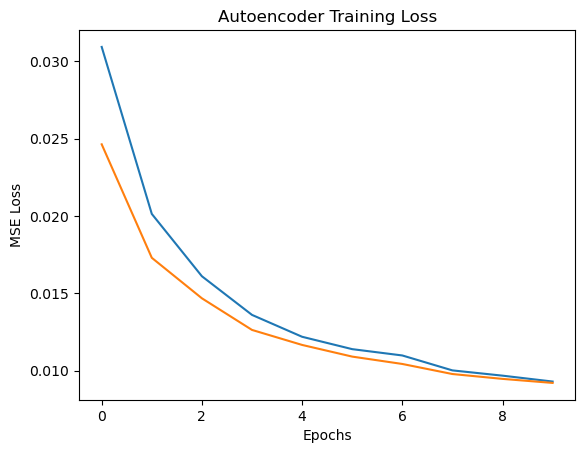

In [10]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.show()

In [11]:
train_reconstruction = model.predict(normal_train_images, verbose=0)

train_error = np.mean(np.square(normal_train_images - train_reconstruction),axis=1)

print("Reconstruction Error:", train_error[:10])

Reconstruction Error: [0.00463434 0.00842435 0.00728512 0.01737138 0.00783258 0.01664133
 0.00867273 0.00741524 0.00906179 0.00933968]


In [12]:
threshold = np.percentile(train_error, 95)

print("Threshold:", threshold)

Threshold: 0.017137405873442757


In [13]:
test_reconstruction = model.predict(test_images, verbose=0)

test_error = np.mean(np.square(test_images - test_reconstruction),axis=1)

predicted_labels = (test_error > threshold).astype(int)

actual_labels = (test_labels == 24).astype(int)

print("Predicted Classes:", predicted_labels[:20])

Predicted Classes: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [14]:
print("Actual samples:", len(actual_labels))
print("Predicted samples:", len(predicted_labels))

print("\nConfusion Matrix:")
print(confusion_matrix(actual_labels, predicted_labels))

print("\nClassification Report:")
print(classification_report(actual_labels, predicted_labels))

print("\nNumber of anomalies detected:", predicted_labels.sum())

Actual samples: 7172
Predicted samples: 7172

Confusion Matrix:
[[6484  356]
 [ 303   29]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.95      0.95      6840
           1       0.08      0.09      0.08       332

    accuracy                           0.91      7172
   macro avg       0.52      0.52      0.52      7172
weighted avg       0.91      0.91      0.91      7172


Number of anomalies detected: 385


In [ ]:
# 3F yg
# 1. Import libraries
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, classification_report


# 2. Load dataset
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")


# 3. Separate features and labels
x_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values


# 4. Normalize data
x_train = x_train / 255.0
x_test = x_test / 255.0


# 5. Select normal classes (exclude label 24)
x_train_normal = x_train[y_train != 24]

print("Normal Training Data:", x_train_normal.shape)


# 6. Build Autoencoder model
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(784, activation='sigmoid')
])

model.summary()


# 7. Compile model
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)


# 8. Train model
history = model.fit(
    x_train_normal,
    x_train_normal,
    epochs=10,
    batch_size=256,
    validation_split=0.2,
    shuffle=True
)


# 9. Calculate training reconstruction error
train_pred = model.predict(x_train_normal, verbose=0)

train_error = np.mean(
    np.square(x_train_normal - train_pred), axis=1
)


# 10. Set anomaly threshold
threshold = np.percentile(train_error, 95)

print("Threshold:", threshold)


# 11. Calculate testing reconstruction error
test_pred = model.predict(x_test, verbose=0)

test_error = np.mean(
    np.square(x_test - test_pred), axis=1
)


# 12. Detect anomalies
y_pred = (test_error > threshold).astype(int)

y_actual = (y_test == 24).astype(int)


# 13. Display results
print("Anomalies Detected:", np.sum(y_pred == 1))

print("Confusion Matrix:")
print(confusion_matrix(y_actual, y_pred))

print("Classification Report:")
print(classification_report(
    y_actual, y_pred, zero_division=0
))


# 14. Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Autoencoder Loss")
plt.legend()
plt.show()